# Sri Lankan Food Price Forecasting with Ensemble Learning
**CM4371 – Machine Learning & Pattern Recognition · Hands-on Assignment (Ensemble Learning Dashboard)**
Author: J.A.M. Kodikara (224107M) · University of Moratuwa

**Question.** Can ensemble models forecast *next month's retail price* of a food item in a Sri Lankan market better than simply assuming it stays the same, and which kind of ensemble (bagging, boosting, stacking, hybrid) does it best?

**Data.** WFP Sri Lanka Food Prices (via the Humanitarian Data Exchange): monthly retail food prices recorded in LKR per reported unit, market and commodity.

**Models compared:** Bagging (Random Forest) · Boosting (GBM, XGBoost, CatBoost) · Stacking · Hybrids (RF+ARIMA, RF+ANN) · Baselines (naive, ARIMA only, Ridge).

> ### Generative AI disclosure
> The original project code was developed with the help of Claude (Anthropic). Code review, leakage corrections, notebook repair, documentation changes and dashboard improvements were additionally assisted by ChatGPT (OpenAI).

## 1. Code: data preparation, features and models
The reusable modelling implementation is in the **included** `foodprice.py` module, imported by the notebook and dashboard. Keep `foodprice.py` alongside this notebook and `app.py`. This notebook executes the full pipeline, compares methods, interprets results and writes refreshed model artefacts; it does not create the source module.

In [13]:
from pathlib import Path
from foodprice import *
import matplotlib.pyplot as plt, joblib, json, time
Path('figs').mkdir(parents=True, exist_ok=True)
Path('models').mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

## 2. Load the data and explore it

In [14]:
DATA = 'data/wfp_food_prices_lka.csv'   # change path if running on Colab
g = load_clean(DATA)
print(g.shape, g.month.min(), '->', g.month.max())
print(g.commodity.nunique(), 'commodities,', g.market.nunique(), 'markets')

(28925, 9) 2023-01 -> 2025-09
35 commodities, 38 markets


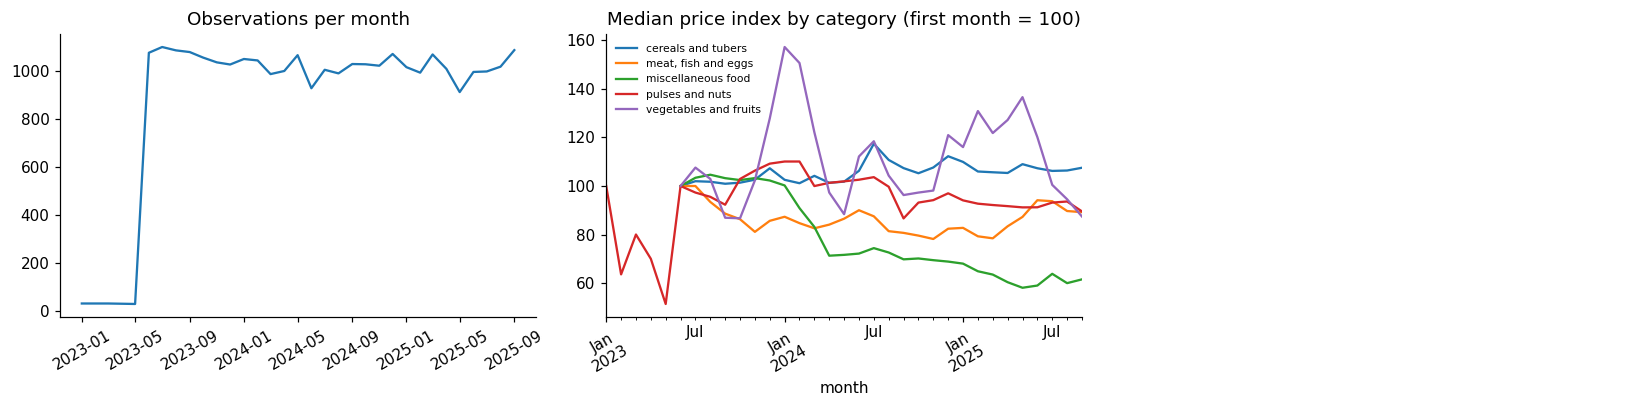

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
# coverage
cov = g.groupby('month').size(); cov.index = cov.index.to_timestamp()
ax[0].plot(cov.index, cov.values); ax[0].set_title('Observations per month'); ax[0].tick_params(axis='x', rotation=30)
# price index by category
keep = g.groupby(['market','commodity']).month.transform('nunique') >= MIN_OBS
gg = g[keep].sort_values('month').copy()
gg['idx'] = gg.price / gg.groupby(['market','commodity']).price.transform('first') * 100
ci = gg.groupby(['category','month']).idx.median().unstack(0); ci.index = ci.index.to_timestamp()
ci.plot(ax=ax[1], legend=False); ax[1].set_title('Median price index by category (first month = 100)'); ax[1].tick_params(axis='x', rotation=30)
ax[1].legend(fontsize=7, frameon=False)
# volatility is built after the panel
ax[2].axis('off')
plt.tight_layout(); plt.savefig('figs/eda1.png'); plt.show()

## 3. Build the panel and split by time
The **last six observed months (Apr–Sep 2025) are the test set**, and earlier months are training. The source has missing months for some market–commodity pairs. To avoid leakage, we **do not interpolate from later prices**, and we only evaluate one-step forecasts where the previous three observed calendar months have valid prices. National features and ARIMA use only historical observations. A chronological split prevents using future target months for model fitting.

In [16]:
panel = build_panel(g)
lab = panel[panel.obs & panel.dy.notna()].copy()          # rows with a real, observed target
cats = get_categories(panel)
tmax = lab.t.max()
test, train = lab[lab.t > tmax - 6].copy(), lab[lab.t <= tmax - 6].copy()
print('series:', lab.groupby(['market','commodity']).ngroups, '| train rows:', len(train), '| test rows:', len(test))
print('train', train.month.min(), '->', train.month.max(), '| test', test.month.min(), '->', test.month.max())

series: 904 | train rows: 11305 | test rows: 4509
train 2023-09 -> 2025-03 | test 2025-04 -> 2025-09


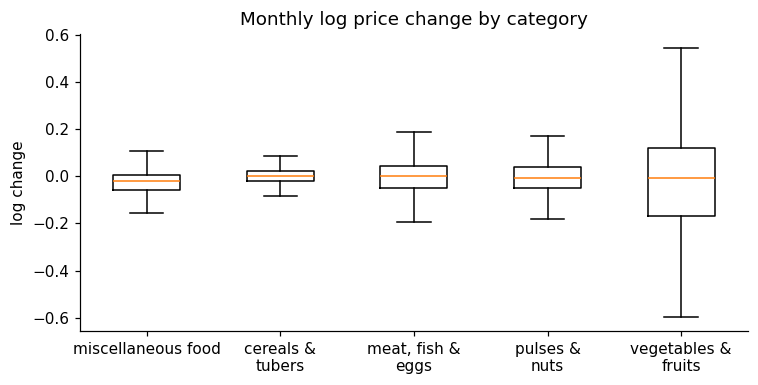

category
miscellaneous food       0.062
cereals and tubers       0.086
meat, fish and eggs      0.095
pulses and nuts          0.173
vegetables and fruits    0.277
Name: dy, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = lab.groupby('category').dy.std().sort_values().index
ax.boxplot([lab[lab.category == c].dy.clip(-1, 1) for c in order], tick_labels=[c.replace(' and ', ' &\n') for c in order], showfliers=False)
ax.set_title('Monthly log price change by category'); ax.set_ylabel('log change'); plt.tight_layout(); plt.savefig('figs/eda2.png'); plt.show()
print(lab.groupby('category').dy.std().round(3).sort_values())

Vegetables & fruits are far more volatile month to month than cereals. This matters later: it decides where a model can actually add value over the naive baseline.

## 4. Train and compare all models
Each model is trained on the training months only and scored on the 6 unseen test months.

In [18]:
models, rows, fitted = build_all(cats), {}, {}
for name, m in models.items():
    t0 = time.time(); m.fit(train, train.dy.values); fitted[name] = m
    rows[name] = {**metrics(test, m.predict(test)), 'Family': FAMILY[name], 'Train time (s)': time.time() - t0}
    print(f'{name:22s} done in {time.time()-t0:5.1f}s')
res = pd.DataFrame(rows).T
res[['MAE (LKR)','RMSE (LKR)','MAPE (%)','R2','Direction acc. (%)','Train time (s)']] = res[['MAE (LKR)','RMSE (LKR)','MAPE (%)','R2','Direction acc. (%)','Train time (s)']].astype(float)
res = res.sort_values('MAE (LKR)'); res.round(3)

Naive (last month)     done in   0.0s
ARIMA only             done in   0.0s
Ridge (linear)         done in   0.0s
Random Forest          done in   1.5s
GBM                    done in   5.0s
XGBoost                done in   0.5s
CatBoost               done in   1.2s
Stacking               done in   7.8s
Hybrid RF+ARIMA        done in   1.5s
Hybrid RF+ANN          done in   2.3s


,MAE (LKR),RMSE (LKR),MAPE (%),R2,Direction acc. (%),Family,Train time (s)
Random Forest,65.521,111.896,12.075,0.974,56.420,Bagging,1.531
Stacking,65.601,111.413,11.573,0.974,53.360,Stacking,7.788
CatBoost,65.818,114.368,11.686,0.973,59.437,Boosting,1.159
Naive (last month),66.758,114.155,12.391,0.973,NaN,Baseline,0.002
Hybrid RF+ARIMA,67.223,113.943,12.332,0.973,57.197,Hybrid,1.550
ARIMA only,67.607,116.353,12.335,0.972,56.066,Baseline,0.001
Hybrid RF+ANN,68.108,113.551,12.327,0.974,58.261,Hybrid,2.271
XGBoost,68.964,119.297,12.167,0.971,55.179,Boosting,0.490
GBM,69.804,119.144,12.414,0.971,53.560,Boosting,4.993
Ridge (linear),75.791,118.270,14.139,0.971,55.910,Baseline,0.042


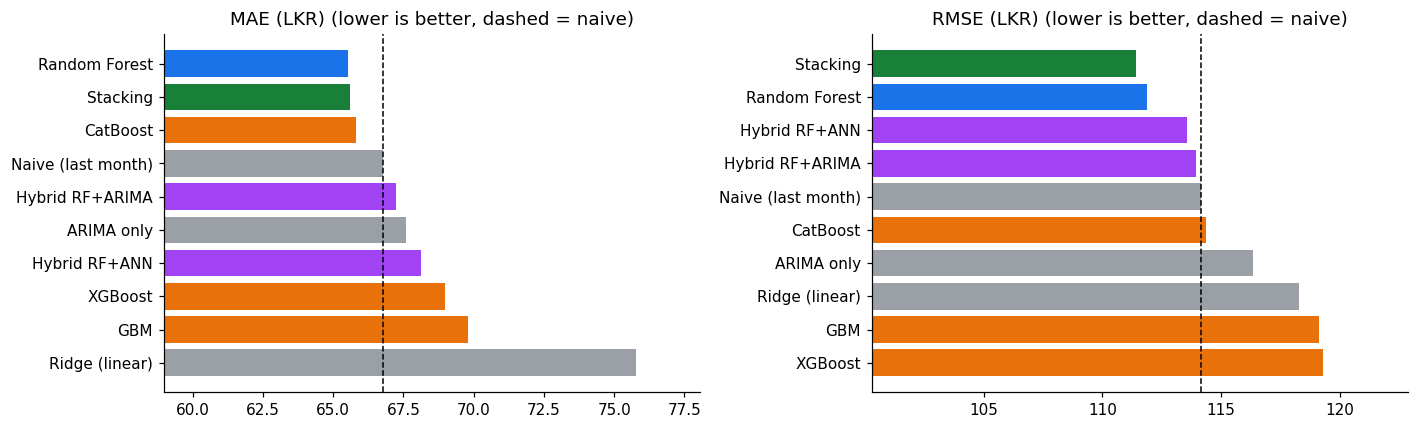

Stacking meta-model weights: {'Random Forest': np.float64(0.096), 'XGBoost': np.float64(0.171), 'CatBoost': np.float64(0.0), 'Ridge': np.float64(0.082)}


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
col = {'Baseline':'#9aa0a6','Bagging':'#1a73e8','Boosting':'#e8710a','Stacking':'#188038','Hybrid':'#a142f4'}
for a, metric in zip(ax, ['MAE (LKR)', 'RMSE (LKR)']):
    r = res.sort_values(metric, ascending=False)
    a.barh(r.index, r[metric], color=[col[f] for f in r.Family]); a.set_xlim(r[metric].min()*0.9, r[metric].max()*1.03)
    a.axvline(res.loc['Naive (last month)', metric], color='k', ls='--', lw=1); a.set_title(metric + ' (lower is better, dashed = naive)')
plt.tight_layout(); plt.savefig('figs/comparison.png'); plt.show()
print('Stacking meta-model weights:', fitted['Stacking'].weights)

## 5. Why did the models behave this way? Error analysis

In [20]:
P = test.copy()
for n, m in fitted.items(): P[n] = to_price(test, m.predict(test))
for n in fitted: P['ae_' + n] = (P.price - P[n]).abs()
show = ['Naive (last month)', 'ARIMA only', 'Random Forest', 'CatBoost', 'Stacking', 'Hybrid RF+ARIMA']
by_cat = P.groupby('category')[['ae_' + n for n in show]].mean(); by_cat.columns = show
by_cat['rows'] = P.category.value_counts(); by_cat.round(1)

,Naive (last month),ARIMA only,Random Forest,CatBoost,Stacking,Hybrid RF+ARIMA,rows
category,,,,,,,
cereals and tubers,8.4,8.3,10.7,10.6,9.6,10.1,474
"meat, fish and eggs",95.6,95.6,92.8,94.8,97.8,93.3,1342
miscellaneous food,33.9,36.2,31.7,30.6,32.0,31.3,171
pulses and nuts,49.4,51.6,52.1,51.0,50.5,52.4,650
vegetables and fruits,69.8,71.0,67.6,67.4,65.0,71.4,1872


In [21]:
# Descriptive gain and an exploratory month-block bootstrap. All markets may
# share shocks in a given month, so independently resampling series would
# incorrectly treat correlated observations as independent evidence.
best = res.index[0] if res.index[0] != 'Naive (last month)' else res.index[1]
P['gain'] = P['ae_Naive (last month)'] - P['ae_' + best]
sr = P.groupby(['market', 'commodity']).gain.mean().values
monthly_gain = P.groupby('month').gain.mean().values
rng = np.random.default_rng(0)
bs = np.array([rng.choice(monthly_gain, len(monthly_gain), replace=True).mean() for _ in range(3000)])
weighted_gain = float(P.gain.mean())
print(f'Best model: {best}. Test-row-weighted MAE gain over naive = {weighted_gain:.2f} LKR')
print(f'Exploratory month-bootstrap 95% interval: [{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}] LKR (only {len(monthly_gain)} months; not conclusive)')
print(f'Average series-level gain = {sr.mean():.2f} LKR; share of series with a positive mean gain = {(sr > 0).mean():.0%}')
mm = P.groupby('month')[['ae_Naive (last month)', 'ae_' + best]].mean().round(1); mm

Best model: Random Forest. Test-row-weighted MAE gain over naive = 1.24 LKR
Exploratory month-bootstrap 95% interval: [-5.66, 8.39] LKR (only 6 months; not conclusive)
Average series-level gain = 0.28 LKR; share of series with a positive mean gain = 44%


,ae_Naive (last month),ae_Random Forest
month,,
2025-04,79.4,83.6
2025-05,65.2,76.5
2025-06,80.6,66.2
2025-07,75.7,63.9
2025-08,49.3,50.7
2025-09,49.2,49.8


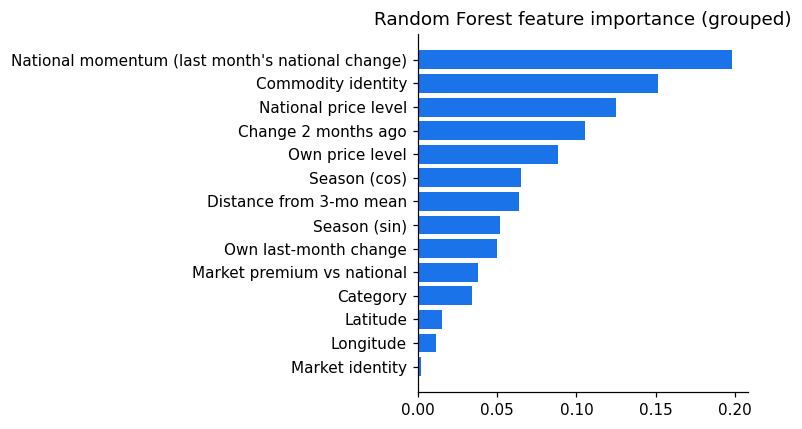

nd1          0.198
commodity    0.151
ln1          0.125
d2           0.105
lp1          0.088
mcos         0.065
mrev         0.064
msin         0.052
d1           0.050
prem         0.038
category     0.034
lat          0.015
lon          0.011
market       0.002
dtype: float64

In [22]:
rf = fitted['Random Forest'].est
names = encode(train.head(2), cats).columns
imp = pd.Series(rf.feature_importances_, index=names)
grp = imp.groupby(lambda c: c.split('_')[0] if c.startswith(('commodity_','market_','category_')) else c).sum().sort_values()
lab_map = {'nd1':'National momentum (last month\'s national change)','ln1':'National price level','mcos':'Season (cos)','msin':'Season (sin)','d2':'Change 2 months ago','lp1':'Own price level','mrev':'Distance from 3-mo mean','d1':'Own last-month change','prem':'Market premium vs national','commodity':'Commodity identity','category':'Category','market':'Market identity','lat':'Latitude','lon':'Longitude'}
fig, ax = plt.subplots(figsize=(7, 4)); ax.barh([lab_map.get(i, i) for i in grp.index], grp.values, color='#1a73e8')
ax.set_title('Random Forest feature importance (grouped)'); plt.tight_layout(); plt.savefig('figs/importance.png'); plt.show()
grp.sort_values(ascending=False).round(3)

## 6. Interpretation
The live numeric results and confidence interval are generated above; this discussion should be read alongside them.

**Problem and baseline.** Retail food prices are persistent, so the naive one-month forecast (next month's price equals the previous observed month's price) is a strong baseline. We predict the next **log price change**, not the raw price. MAE and RMSE are measured in LKR per commodity's reported selling unit, so they average errors across kg and per-item commodities rather than representing a single shared price unit.

**Comparing ensemble families.** Random Forest represents bagging, while GBM, XGBoost and CatBoost represent boosting. Stacking learns a meta-model from forward-chaining out-of-fold base-model predictions; RF+ARIMA and RF+ANN explore two hybrid strategies. Compare the *observed* MAE and RMSE in the output table. Random Forest averaging may reduce variance in noisy month-to-month changes; boosting may capture patterns that trees miss but can also fit transient fluctuations. These are possible explanations, not causal conclusions established by one held-out period.

**Stacking and hybrids.** Stacking may struggle to improve when its base models use the same historical features and make correlated mistakes. The RF+ARIMA approach models national movement with ARIMA and market-specific residuals with a forest, while RF+ANN averages independent estimators. Whether each helps is shown in the saved comparison table; no hybrid improvement is guaranteed.

**Where improvements occur.** The category comparison distinguishes price groups. Per-series advantages can differ from the overall test-row-weighted improvement because each series may contribute a different number of evaluated months.

**Uncertainty and limitations.** We use six consecutive months (Apr–Sep 2025) for testing. The month-block bootstrap interval is exploratory only because there are just six blocks and market prices may be correlated. These results cannot establish statistical superiority in other years or under different economic conditions. The missing-month policy excludes rows without three consecutive prior observations, and so can change sample coverage. Model hyperparameters were not exhaustively tuned, and rainfall, fuel costs and exchange rates are not included. The 'next month' explorer forecasts **October 2025**, the month following the end of the available historical data—not the current calendar month.

**Future work.** Evaluate more rolling forecast origins, add external drivers where historically available, tune with time-aware cross-validation, inspect forecast calibration, and test robustness across commodities and price units.

## 7. Save everything the dashboard needs
The models above were evaluated on the held-out six months. For the dashboard's **October 2025 historical next-month forecast**, they are refit on all observed months through September 2025. The evaluation statistics remain those from training-only fits; they are not recomputed on data used for training.

In [23]:
P_out = P[['market','commodity','category','unit','month','price'] + list(fitted)].copy()
P_out['month'] = P_out.month.astype(str)
P_out.to_csv('models/test_predictions.csv.gz', index=False)
res.to_csv('models/results.csv'); by_cat.to_csv('models/by_category.csv')
grp.rename(index=lambda i: lab_map.get(i, i)).to_csv('models/importance.csv', header=['importance'])
pd.DataFrame({'series_average_gain':sr}).to_csv('models/series_gain.csv', index=False)
json.dump({'best': best, 'stack_weights': {k: float(v) for k, v in fitted['Stacking'].weights.items()},
           'ci': [float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))],
           'gain': weighted_gain, 'series_average_gain': float(sr.mean()),
           'bootstrap_unit': 'month (six months; exploratory)'}, open('models/summary.json', 'w'))
pn = panel.copy(); pn['month'] = pn.month.astype(str); pn.to_csv('models/panel.csv.gz', index=False)
final = {n: m.fit(lab, lab.dy.values) for n, m in build_all(cats).items()}
joblib.dump({'models': final, 'cats': cats}, 'models/models.joblib', compress=3)
import os; print({f: round(os.path.getsize('models/' + f) / 1e6, 1) for f in os.listdir('models')}, 'MB')

{'summary.json': 0.0, 'series_gain.csv': 0.0, 'by_category.csv': 0.0, 'panel.csv.gz': 1.6, 'models.joblib': 100.9, 'results.csv': 0.0, 'importance.csv': 0.0, 'test_predictions.csv.gz': 0.4} MB


The resulting `models/` folder contains the saved comparison results and deployable models. Start the dashboard from the project directory using `streamlit run app.py`. Review the limitations and the explicit AI disclosure above before submitting.